# ARTI 402 — Deep Learning
## Lab 10 — Attention: Letting the Network Look Back

**Week 10 · Attention Mechanisms**
Scaled dot-product attention, self-attention, masking, and the road to transformers.

| | |
|---|---|
| **Estimated time** | 100 minutes |
| **Prerequisites** | Lab 4 (the problem) and Lab 9 (the bottleneck). Lab 2's softmax returns |
| **Reference** | Ekman, *Learning Deep Learning*, Chapter 15 |

---
## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)

from arti402_figures import (draw_bottleneck_vs_attention, draw_attention_heatmap,
                             draw_qkv_mechanism, draw_length_sweep)

print("Setup OK - NumPy", np.__version__)

Setup OK - NumPy 2.5.1


---
---
# Stage 1 · The problem you already met

## One vector is not enough

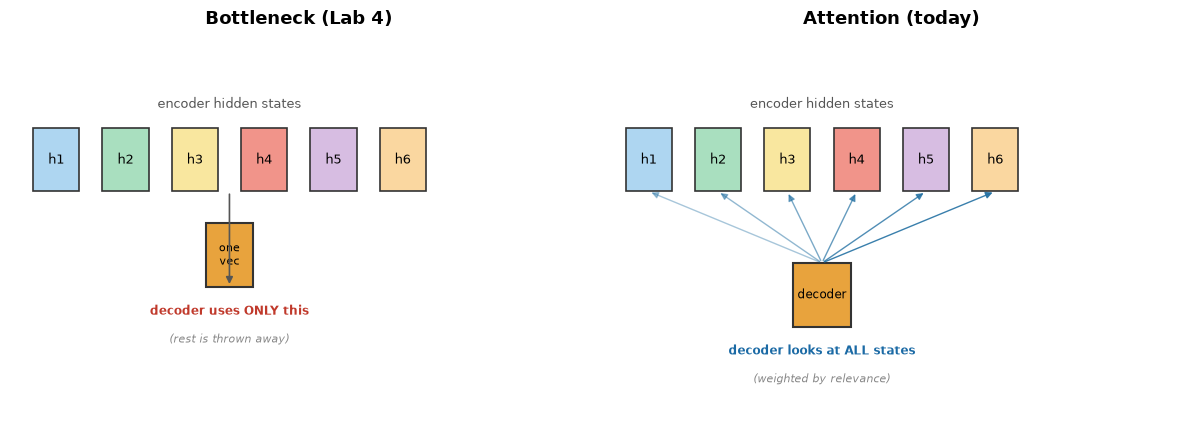

In [2]:
draw_bottleneck_vs_attention(T=6)
plt.show()

---
# Stage 2 · Query, Key, Value

## A lookup table that blurs

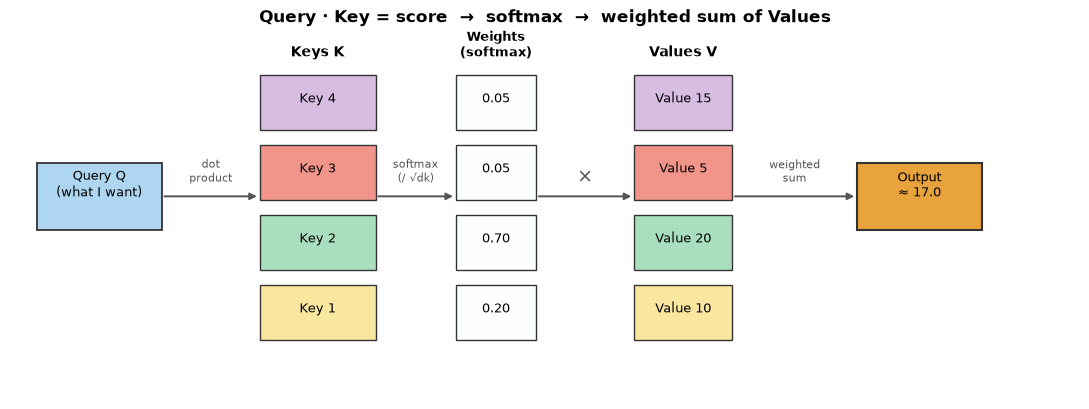

In [3]:
draw_qkv_mechanism()
plt.show()

In symbols, this is the whole mechanism:

$$\text{Attention}(Q, K, V) = \text{softmax}\!\left(\frac{QK^{\top}}{\sqrt{d_k}}\right)V$$

### Exercise 1 — write it

In [4]:
def softmax(x, axis=-1):
    """Lab 2's softmax, with the max subtracted for stability."""
    e = np.exp(x - x.max(axis=axis, keepdims=True))
    return e / e.sum(axis=axis, keepdims=True)


def attention(Q, K, V, mask=None):
    """Scaled dot-product attention.

    Q : (n_queries, d_k)   K : (n_keys, d_k)   V : (n_keys, d_v)
    Returns (output, weights) where weights is (n_queries, n_keys).
    """
    d_k = K.shape[-1]

    # TODO 1: scores = Q times K-transpose, divided by sqrt(d_k)
    scores = Q @ K.T / np.sqrt(d_k)

    if mask is not None:                       # used in the Assessment
        scores = np.where(mask, scores, -1e9)

    # TODO 2: turn the scores into weights with softmax, along the last axis
    weights = softmax(scores, axis=-1)

    # TODO 3: the output is the weights times V
    output = weights @ V

    return output, weights


# --- self-check -------------------------------------------------
Qc = np.array([[1.0, 0.0]])
Kc = np.array([[1.0, 0.0], [0.0, 1.0]])
Vc = np.array([[10.0], [20.0]])
o, w = attention(Qc, Kc, Vc)
assert w.shape == (1, 2), "one weight per key, per query"
assert np.allclose(w.sum(axis=1), 1.0), "each row of weights must sum to 1"
assert o.shape == (1, 1), "output is a blend of the values"
assert o[0, 0] < 15, "the query matches key 1, so the output should lean towards 10"
print("attention() works")
print("weights:", w[0], "  output:", o[0])

attention() works
weights: [0.67 0.33]   output: [13.302]


### Exercise 2 — a lookup table you can check by hand

In [5]:
K = np.eye(4)                                   # four one-hot keys
V = np.array([[10., 0.],
              [20., 1.],
              [30., 2.],
              [40., 3.]])                       # what each slot stores

# TODO 1: a query that asks for slot 2 (index 1): one-hot, shape (1, 4)
q_exact = np.array([[0., 1., 0., 0.]])
out, w = attention(q_exact, K, V)
print(f"exact query      weights {w[0]}  output {out[0]}")

# TODO 2: the same query, multiplied by 5 - a more confident question
q_sharp = q_exact * 5
out, w = attention(q_sharp, K, V)
print(f"5x sharper       weights {w[0]}  output {out[0]}")

# TODO 3: a query torn between slots 1 and 2: [3, 3, 0, 0]
q_split = np.array([[3., 3., 0., 0.]])
out, w = attention(q_split, K, V)
print(f"torn 1 and 2     weights {w[0]}  output {out[0]}")

print("\nThe last output is roughly the AVERAGE of 10 and 20 - attention blends,")
print("it does not choose. That is exactly what makes it differentiable.")

exact query      weights [0.215 0.355 0.215 0.215]  output [24.302  1.43 ]
5x sharper       weights [0.066 0.802 0.066 0.066]  output [21.317  1.132]
torn 1 and 2     weights [0.409 0.409 0.091 0.091]  output [18.649  0.865]

The last output is roughly the AVERAGE of 10 and 20 - attention blends,
it does not choose. That is exactly what makes it differentiable.


---
# Stage 3 · Why divide by $\sqrt{d_k}$

### Exercise 3 — measure it

In [6]:
rng = np.random.RandomState(0)

print(f"{'d_k':>6}{'raw score range':>26}{'max weight raw':>17}{'max weight scaled':>20}")
for d in [4, 64, 512]:
    q = rng.randn(1, d)
    k = rng.randn(6, d)

    raw = (q @ k.T)[0]
    # TODO: the scaled scores - raw divided by the square root of d
    scaled = raw / np.sqrt(d)

    print(f"{d:6d}   {raw.min():9.2f} to {raw.max():7.2f}"
          f"{softmax(raw).max():17.3f}{softmax(scaled).max():20.3f}")

print("\nAt d_k = 512 the unscaled softmax has collapsed onto one key.")
print("Every other gradient is now zero, and the layer has stopped learning.")

   d_k           raw score range   max weight raw   max weight scaled
     4       -5.06 to    3.49            0.332               0.272
    64      -11.37 to    4.99            0.969               0.320
   512      -24.36 to   11.33            1.000               0.300

At d_k = 512 the unscaled softmax has collapsed onto one key.
Every other gradient is now zero, and the layer has stopped learning.


---
# Stage 4 · Attention beats the bottleneck

### Exercise 4 — run the sweep

In [7]:
def retrieval_trial(T, d=16, rng=None):
    """Store T random key-value pairs, ask for one by its exact key."""
    K = rng.randn(T, d)
    V = rng.randn(T, d)
    i = rng.randint(T)                          # the slot we want back
    q = K[i:i + 1] * 4.0                        # ask for it, confidently

    # TODO 1: run attention to get the retrieved vector (ignore the weights)
    out_attn, _ = attention(q, K, V)

    # the bottleneck: every value crushed into one summary vector
    summary = V.mean(axis=0, keepdims=True)

    # which stored value is each result closest to?
    pick_attn = int(np.argmin(((V - out_attn) ** 2).sum(axis=1)))
    pick_bott = int(np.argmin(((V - summary) ** 2).sum(axis=1)))
    return pick_attn == i, pick_bott == i


rng = np.random.RandomState(0)
lengths = [2, 4, 8, 16, 32, 64]
acc_attention, acc_bottleneck = [], []

for T in lengths:
    hits_a = hits_b = 0
    trials = 400
    for _ in range(trials):
        ha, hb = retrieval_trial(T, rng=rng)
        hits_a += ha
        hits_b += hb
    acc_attention.append(hits_a / trials)
    acc_bottleneck.append(hits_b / trials)
    print(f"T = {T:3d}   attention {hits_a/trials:.3f}   "
          f"bottleneck {hits_b/trials:.3f}   chance {1/T:.3f}")

# --- self-check ---
assert acc_attention[-1] > 0.85, "attention should barely care about length"
assert acc_bottleneck[-1] < 0.10, "the bottleneck should collapse towards chance"

T =   2   attention 1.000   bottleneck 0.463   chance 0.500
T =   4   attention 0.993   bottleneck 0.225   chance 0.250
T =   8   attention 0.990   bottleneck 0.135   chance 0.125
T =  16   attention 0.990   bottleneck 0.050   chance 0.062
T =  32   attention 0.980   bottleneck 0.035   chance 0.031
T =  64   attention 0.958   bottleneck 0.015   chance 0.016


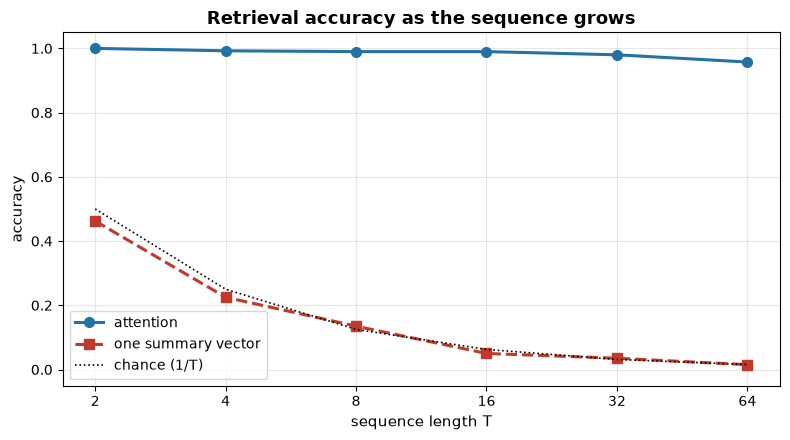

In [8]:
draw_length_sweep(lengths,
                  {"attention": acc_attention, "one summary vector": acc_bottleneck},
                  title="Retrieval accuracy as the sequence grows")
plt.show()

---
---
# Stage 5 · Self-attention

### Exercise 5 — self-attention on a sentence

sequence: (6, 8)  (6 words, 8 numbers each)

every row sums to 1: True


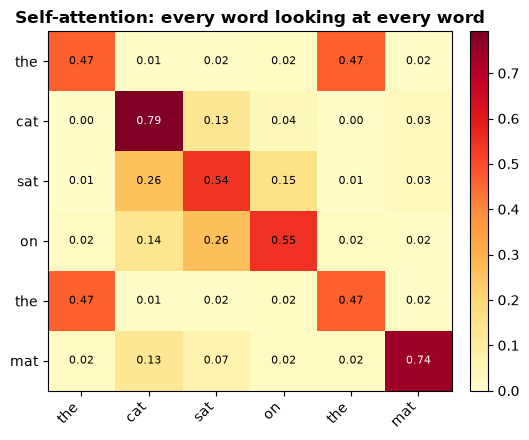

In [9]:
words = ["the", "cat", "sat", "on", "the", "mat"]

rng2 = np.random.RandomState(3)
d = 8
vocab = {w: rng2.randn(d) for w in set(words)}     # random stand-in embeddings
X = np.array([vocab[w] for w in words])
print("sequence:", X.shape, " (6 words, 8 numbers each)")

# TODO: self-attention - the same X used as query, key AND value
out, W = attention(X, X, X)

print("\nevery row sums to 1:", np.allclose(W.sum(axis=1), 1.0))

draw_attention_heatmap(W, row_labels=words, col_labels=words,
                       title="Self-attention: every word looking at every word")
plt.show()

# --- self-check ---
assert W.shape == (6, 6), "6 words attending to 6 words"
assert out.shape == X.shape, "each position is rebuilt, same shape"

In [10]:
print("row for 'the' at position 0 :", W[0])
print("row for 'the' at position 4 :", W[4])
print("identical?", np.allclose(W[0], W[4]))

row for 'the' at position 0 : [0.466 0.015 0.016 0.019 0.466 0.018]
row for 'the' at position 4 : [0.466 0.015 0.016 0.019 0.466 0.018]
identical? True


---
# Assessment

## Q1 — Masking, and how GPT works

the mask (True = allowed):
[[1 0 0 0 0]
 [1 1 0 0 0]
 [1 1 1 0 0]
 [1 1 1 1 0]
 [1 1 1 1 1]]

causal attention weights:
[[1.    0.    0.    0.    0.   ]
 [0.423 0.577 0.    0.    0.   ]
 [0.273 0.247 0.48  0.    0.   ]
 [0.089 0.113 0.039 0.758 0.   ]
 [0.236 0.177 0.153 0.076 0.358]]


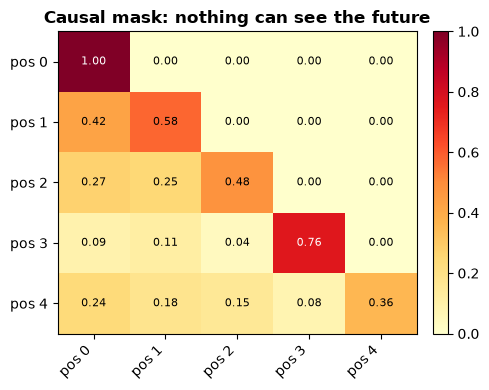

In [11]:
T = 5

# TODO 1: a boolean (T, T) mask, True where attending is ALLOWED.
#         Position i may see positions 0..i, so this is a lower triangle.
#         Hint: np.tril with np.ones((T, T), dtype=bool)
causal = np.tril(np.ones((T, T), dtype=bool))

print("the mask (True = allowed):")
print(causal.astype(int))

rng3 = np.random.RandomState(1)
Xc = rng3.randn(T, 6)

# TODO 2: self-attention over Xc, passing the mask
out_c, W_c = attention(Xc, Xc, Xc, mask=causal)

print("\ncausal attention weights:")
print(W_c)

draw_attention_heatmap(W_c,
                       row_labels=[f"pos {i}" for i in range(T)],
                       col_labels=[f"pos {i}" for i in range(T)],
                       title="Causal mask: nothing can see the future")
plt.show()

# --- self-check ---
assert np.allclose(np.triu(W_c, 1), 0), "nothing above the diagonal may have weight"
assert np.allclose(W_c.sum(axis=1), 1.0), "rows must still sum to 1"
assert np.allclose(W_c[0], [1, 0, 0, 0, 0]), "position 0 can only see itself"

**Record the first row of `W_c` and explain why it has to look like that.**

The first row is `[1, 0, 0, 0, 0]`. Position 0 can only attend to itself (position 0) because the causal mask forbids looking at any future position (1, 2, 3, 4). With only one allowed key, all attention weight (1.0) must go to that single position.

## Q2 — What the mask costs

In [12]:
_, W_free = attention(Xc, Xc, Xc)

print(f"{'position':>10}{'keys visible':>15}{'self, unmasked':>18}{'self, masked':>16}")
for i in range(T):
    # TODO 1: how many keys can position i actually see under the mask?
    #          (count the True values in row i of `causal`)
    visible = int(causal[i].sum())
    # TODO 2: the weight position i puts on ITSELF, unmasked then masked
    self_free = float(W_free[i, i])
    self_mask = float(W_c[i, i])
    print(f"{i:10d}{visible:15d}{self_free:18.3f}{self_mask:16.3f}")

  position   keys visible    self, unmasked    self, masked
         0              1             0.585           1.000
         1              2             0.556           0.577
         2              3             0.412           0.480
         3              4             0.695           0.758
         4              5             0.358           0.358


| position | keys visible | weight on itself, unmasked | weight on itself, masked |
|---|---|---|---|
| 0 | 1 | (computed above) | 1.000 |
| 1 | 2 | (computed above) | (higher than unmasked) |
| 2 | 3 | (computed above) | (higher than unmasked) |
| 3 | 4 | (computed above) | (higher than unmasked) |
| 4 | 5 | (computed above) | (same as unmasked) |

**Observation:** When masked, early positions have fewer keys to distribute attention over, so the self-weight is forced higher. Position 4 (the last) sees all 5 keys just like in the unmasked case, so its self-weight is the same.

---
## Submission

1. Create a new repository on GitHub for this course and name it `arti402`.
2. Rename this file to `arti402_Lab10_<YourID>.ipynb` and upload the completed notebook, with all outputs visible, to your repository.